# Output Verification

Prototype of the output screening in the verification plan (`docs/validation-plan.md`), developed on a few studies. Every section computes its metrics and plots them right away.

In [1]:
import os
import sys
sys.path.append(os.path.join(os.getcwd(), '..'))

import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from scipy.stats import gmean, gstd
from matplotlib.ticker import ScalarFormatter
from babelbetes import data_store, drawing, tdd

%config InlineBackend.figure_format = 'retina'

STORE_PATH = os.path.join(os.getcwd(), '..', 'data', 'out')
STUDIES = ['DCLP3', 'DCLP5', 'Flair', 'IOBP2', 'PEDAP', 'ReplaceBG', 'T1DEXI', 'T1DEXIP']  # all except Loop
STREAMS = ['cgm', 'bolus', 'basal']
KEYS = ['study_name', 'patient_id']
FIGURE_DIR = os.path.join(os.getcwd(), 'figures')
PALETTE = dict(zip(STUDIES, ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#4a3aa7', '#17a2b8', '#8c564b']))


MIN_TDD = 1.0  # U, days below are zero-dose days and not part of the TDD statistics
TOP_N = 3

In [2]:
store = data_store.load(STORE_PATH, data_types=STREAMS, studies=STUDIES, categorical_keys=True)

## Hard Checks

Plan §4 A. The limits hold for every study: the reporting range of Abbott and Dexcom sensors, and the largest bolus and basal maxima across Omnipod, MiniMed and Tandem pumps. Every violation counts; the table lists the top `TOP_N` patients per study and check.

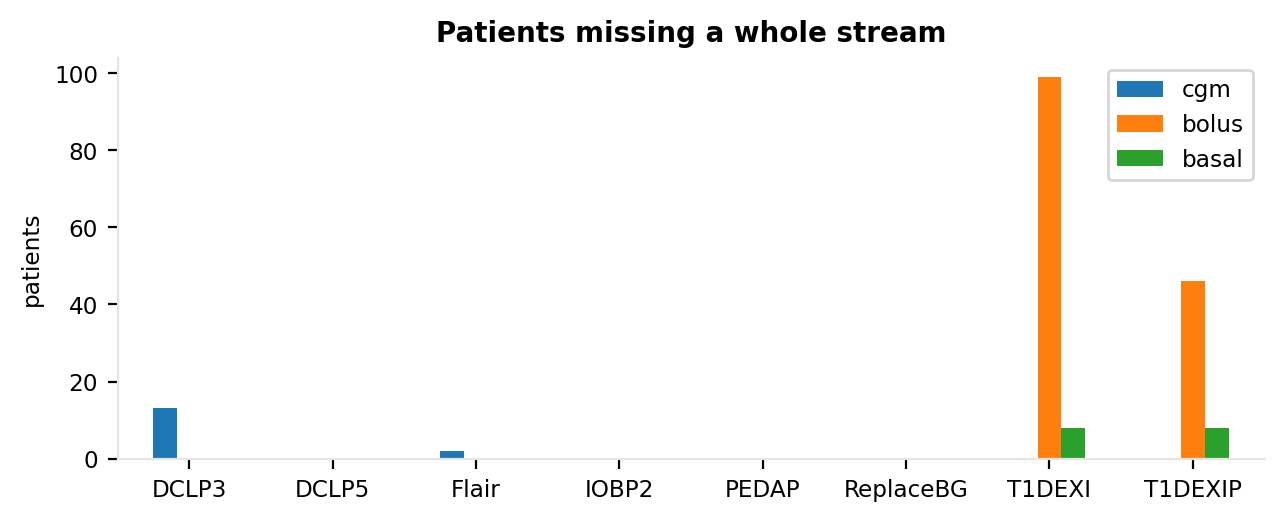

In [3]:
# share of patients per study that miss a whole stream
df_streams = pd.DataFrame({s: store[s].groupby(KEYS, observed=True).size() for s in STREAMS})
df_missing_stream = df_streams.loc[df_streams.isna().any(axis=1)]

f,ax = drawing.default_figure(1 + 0.8 * len(STUDIES), 2.6)
df_missing_stream.isna().groupby('study_name', observed=True).sum().reindex(STUDIES).plot.bar(ax=ax, rot=0)
ax.set(xlabel=None, ylabel='patients', title='Patients missing a whole stream')
f.savefig(os.path.join(FIGURE_DIR, f"verification_missing_streams.png"), dpi=300, bbox_inches="tight")

In [4]:
CGM_RANGE = (40, 400)  # mg/dL, reporting range of Abbott and Dexcom sensors
MAX_BOLUS = 35          # U, largest bolus maximum across Omnipod, MiniMed and Tandem
MAX_BASAL = 35          # U/h, largest basal maximum across Omnipod, MiniMed and Tandem

cgm, basal = store['cgm'], store['basal']
bolus = store['bolus'].sort_values(KEYS + ['datetime'])
# overlapping bolus: delivery still running when the next bolus starts
next_start = bolus.groupby(KEYS, observed=True).datetime.shift(-1)

# share of violating values per patient, one column per check
df_hard = pd.concat([
    cgm[KEYS].assign(cgm_below=cgm.cgm < CGM_RANGE[0], 
                     cgm_above=cgm.cgm > CGM_RANGE[1], 
                     cgm_missing=cgm.cgm.isna()),
    bolus[KEYS].assign(bolus_negative=bolus.bolus < 0, 
                       bolus_above=bolus.bolus > MAX_BOLUS,
                       bolus_overlap=bolus.datetime + bolus.delivery_duration > next_start),
    basal[KEYS].assign(basal_negative=basal.basal_rate < 0, 
                       basal_above=basal.basal_rate > MAX_BASAL),
]).groupby(KEYS, observed=True).mean()

# patients with at least one violation, per study and check
(df_hard > 0).groupby('study_name', observed=True).sum()

,cgm_below,cgm_above,cgm_missing,bolus_negative,bolus_above,bolus_overlap,basal_negative,basal_above
study_name,,,,,,,,
DCLP3,0,0,0,0,0,0,0,0
DCLP5,0,0,0,0,0,0,0,0
Flair,0,0,0,0,0,30,0,0
IOBP2,0,0,0,0,0,0,0,56
PEDAP,0,0,0,0,0,74,0,0
ReplaceBG,0,0,0,0,0,88,0,0
T1DEXI,308,131,0,0,0,105,0,25
T1DEXIP,103,85,0,0,0,38,0,2


In [5]:
# top patients per study and check, by share of violating values
df_violations = df_hard.melt(ignore_index=False, var_name='check', value_name='share').query('share > 0')
(df_violations.sort_values('share', ascending=False)
    .groupby(['study_name', 'check'], observed=True).head(TOP_N)
    .sort_values(['study_name', 'check', 'share'], ascending=[True, True, False]))

check     share
study_name patient_id                         
Flair      120         bolus_overlap  0.001646
           26          bolus_overlap  0.001396
           126         bolus_overlap  0.001283
IOBP2      445           basal_above  0.001065
           184           basal_above  0.000834
           394           basal_above  0.000516
PEDAP      32          bolus_overlap  0.190805
           60          bolus_overlap  0.178931
           36          bolus_overlap   0.10352
ReplaceBG  276         bolus_overlap  0.113696
           213         bolus_overlap  0.047283
           7           bolus_overlap  0.043915
T1DEXI     306           basal_above   0.59322
           174           basal_above  0.454545
           467           basal_above  0.444444
           695         bolus_overlap  0.100775
           1014        bolus_overlap  0.089552
           1365        bolus_overlap  0.082822
           509             cgm_above   0.18638
           1155            cgm_above  0.116226
           963             cgm_above  0.075244
           402             cgm_below  0.028459
           1438            cgm_below  0.025987
           1115            cgm_below  0.015861
T1DEXIP    443           basal_above       0.1
           317           basal_above  0.090909
           496         bolus_overlap  0.123288
           246         bolus_overlap  0.115942
           467         bolus_overlap  0.086207
           525             cgm_above  0.353834
           71              cgm_above  0.091173
           140             cgm_above  0.073573
           254             cgm_below  0.054117
           313             cgm_below  0.013739
           154             cgm_below  0.012543

## Population Checks

### Fit Functions

Robust bivariate lognormal fit per study (MCD). A patient is an outlier when its Mahalanobis distance from the study centre exceeds `THRESHOLD`.

In [6]:
from sklearn.covariance import EmpiricalCovariance, MinCovDet

THRESHOLD = 4.0  # Mahalanobis distance from the study centre that defines an outlier
TOP_N = 3        # subjects above THRESHOLD with the largest distance become outlier candidates


def fit_population(df, log, robust):
    """Bivariate fit of the two columns of df (log values if log=True).

    robust=True estimates the fit from the tightest core of the points (Minimum
    Covariance Determinant), so extreme patients do not pull it; robust=False
    uses the plain mean and covariance.
    """
    X = np.log(df) if log else df
    estimator = MinCovDet(random_state=0) if robust else EmpiricalCovariance()
    return estimator.fit(X)


def find_outliers(df, fit, threshold, log):
    """Mahalanobis distance of every row of df to the fit, and whether it exceeds threshold.

    The distance counts standard deviations from the centre, corrected for the
    shape of the fit. sklearn returns squared distances, hence the sqrt.
    """
    X = np.log(df) if log else df
    distance = pd.Series(np.sqrt(fit.mahalanobis(X)), index=df.index, name='distance')
    return distance > threshold, distance


def plot_confidence_ellipses(fit, ax, log, n_stds=(1, 2, 3), n_points=200, **kwargs):
    """Draw concentric 'n standard deviations away' contours of the fit.

    If log=True, ellipses are built in log space and mapped back through exp(),
    so they appear curved (not true ellipses) in original units.
    """
    mean_x, mean_y = fit.location_
    std_x, std_y = np.sqrt(np.diag(fit.covariance_))
    r = fit.covariance_[0, 1] / (std_x * std_y)

    theta = np.linspace(0, 2 * np.pi, n_points)
    circle = np.vstack([np.sqrt(1 + r) * np.cos(theta), np.sqrt(1 - r) * np.sin(theta)])
    rot = np.array([[np.cos(np.pi/4), -np.sin(np.pi/4)],
                    [np.sin(np.pi/4),  np.cos(np.pi/4)]])
    circle = rot @ circle

    defaults = dict(alpha=0.6, color="black", linestyle="--")
    defaults.update(kwargs)

    lines = []
    label = defaults.pop('label',None)
    for n_std in n_stds:
        ex = circle[0] * std_x * n_std + mean_x
        ey = circle[1] * std_y * n_std + mean_y
        if log:
            ex, ey = np.exp(ex), np.exp(ey)
        if n_std==n_stds[-1]:
            defaults.update(label=label)
        line, = ax.plot(ex, ey, **defaults)
        lines.append(line)

    ax.relim()
    ax.autoscale_view()
    return lines

## TDD

Daily basal, bolus and total dose. Per patient: geometric mean and spread of the TDD over days with at least `MIN_TDD`.

In [7]:
basal = store['basal'].groupby(KEYS, observed=True).apply(tdd.calculate_daily_basal_dose, include_groups=False)
bolus = store['bolus'].groupby(KEYS, observed=True).apply(tdd.calculate_daily_bolus_dose, include_groups=False)
df_tdd = basal.join(bolus, how='outer')
df_tdd['tdd'] = df_tdd[['basal', 'bolus']].sum(axis=1, min_count=1)

### Zero TDDs

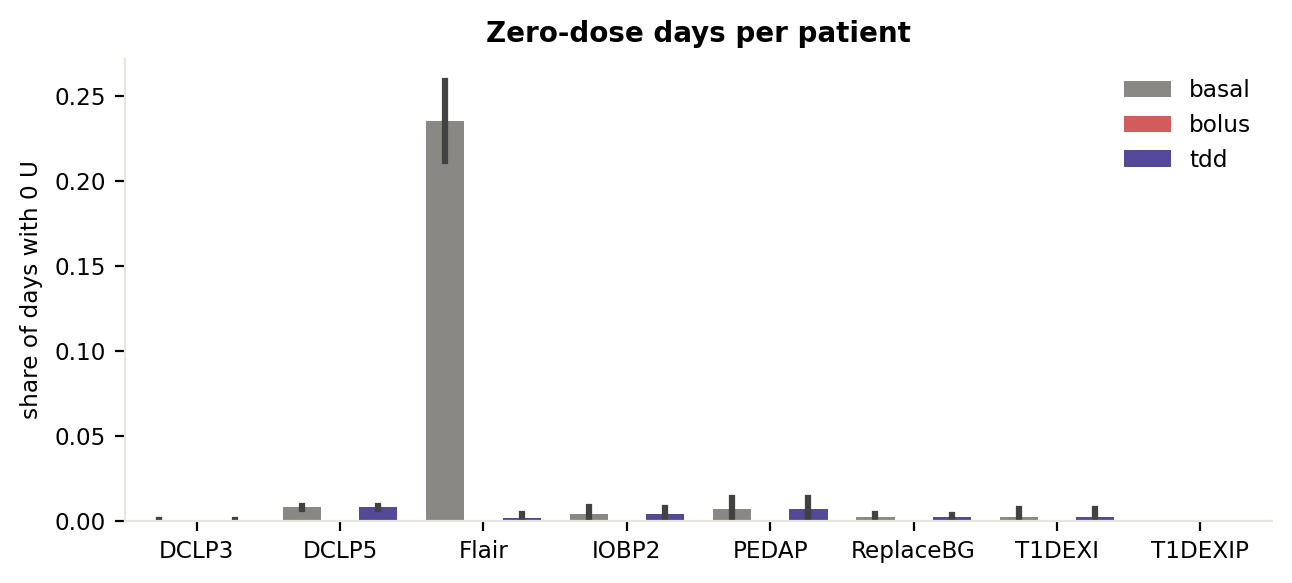

In [8]:
# share of days with no dose at all, per patient
df_zero = (df_tdd == 0).groupby(KEYS, observed=True).mean().melt(ignore_index=False, var_name='dose', value_name='share').reset_index()
palette = {'basal': drawing.colors['Basal'], 'bolus': drawing.colors['Bolus'], 'tdd': '#4a3aa7'}

f, ax = drawing.default_figure(1 + 0.8 * len(STUDIES), 3)
sns.barplot(df_zero, x='study_name', y='share', hue='dose', order=STUDIES, hue_order=list(palette), palette=palette,
            linewidth=0.8, ax=ax)
ax.set(xlabel=None, ylabel='share of days with 0 U', title='Zero-dose days per patient')
ax.legend(title=None, frameon=False)
f.savefig(os.path.join(FIGURE_DIR, f"verification_zero_dose_days.png"), dpi=300, bbox_inches="tight")

### Bolus vs. Basal Ratio

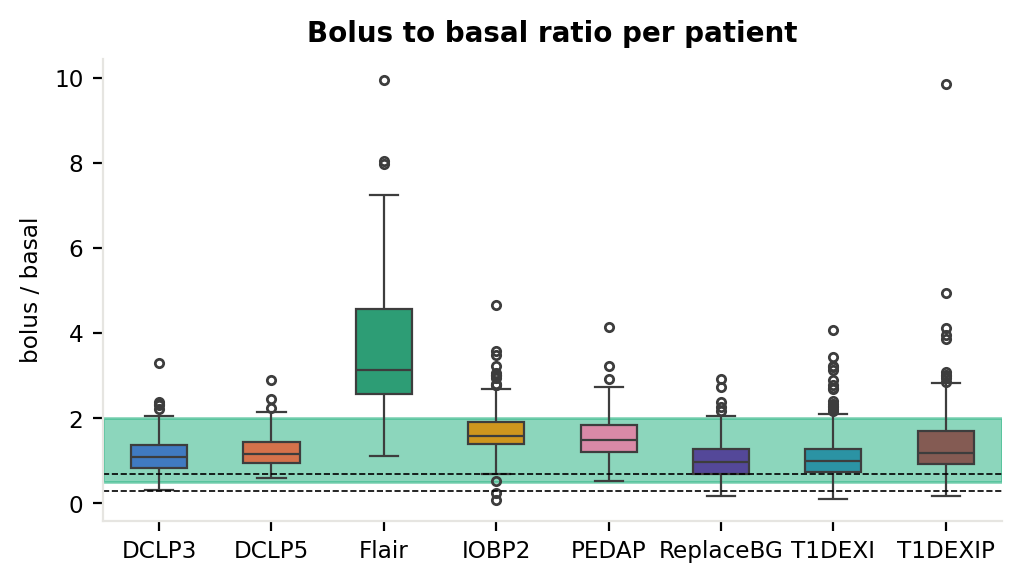

In [9]:
from importlib import reload
reload(drawing)
# bolus/basal ratio per patient: total bolus / total basal over days with both > 0
days = df_tdd[(df_tdd.basal > 0) & (df_tdd.bolus > 0)]
totals = days.groupby(KEYS, observed=True)[['basal', 'bolus']].sum()
df_ratio = (totals.bolus / totals.basal).rename('ratio').reset_index()

f, ax = drawing.default_figure(1 + 0.6 * len(STUDIES), 3)
sns.boxplot(df_ratio, x='study_name', y='ratio', hue='study_name', order=STUDIES, palette=PALETTE,
            flierprops=dict(marker='o', markersize=3), linewidth=0.8, ax=ax,
            width=0.5)
ax.axhline(0.3, color='black', linewidth=0.6, linestyle='--')  # bolus = basal
ax.axhline(0.7, color='black', linewidth=0.6, linestyle='--')  # bolus = basal
ax.axhspan(0.5,2,color=drawing.GREEN,alpha=0.5)
ax.set(xlabel=None, ylabel='bolus / basal', title='Bolus to basal ratio per patient')
ax.yaxis.set_major_formatter('{x:g}')
f.savefig(os.path.join(FIGURE_DIR, f"verification_bolus_basal_ratio.png"), dpi=300, bbox_inches="tight")


### Mean vs. STD

'Study Medians:'

                   mu     sigma
study_name                     
DCLP3       49.180740  1.211145
DCLP5       36.149416  1.223659
Flair       53.578112  1.236999
IOBP2       46.822508  1.298274
PEDAP       13.290725  1.261982
ReplaceBG   41.338510  1.178816
T1DEXI      34.038043  1.167909
T1DEXIP     46.119609  1.165166


'Outliers:'

,,mu,sigma,distance
study_name,patient_id,,,
T1DEXI,1327,5.511680,7.331023,44.128052
T1DEXIP,317,19.617178,5.630423,30.793075
T1DEXI,1,19.353258,2.886862,21.651143


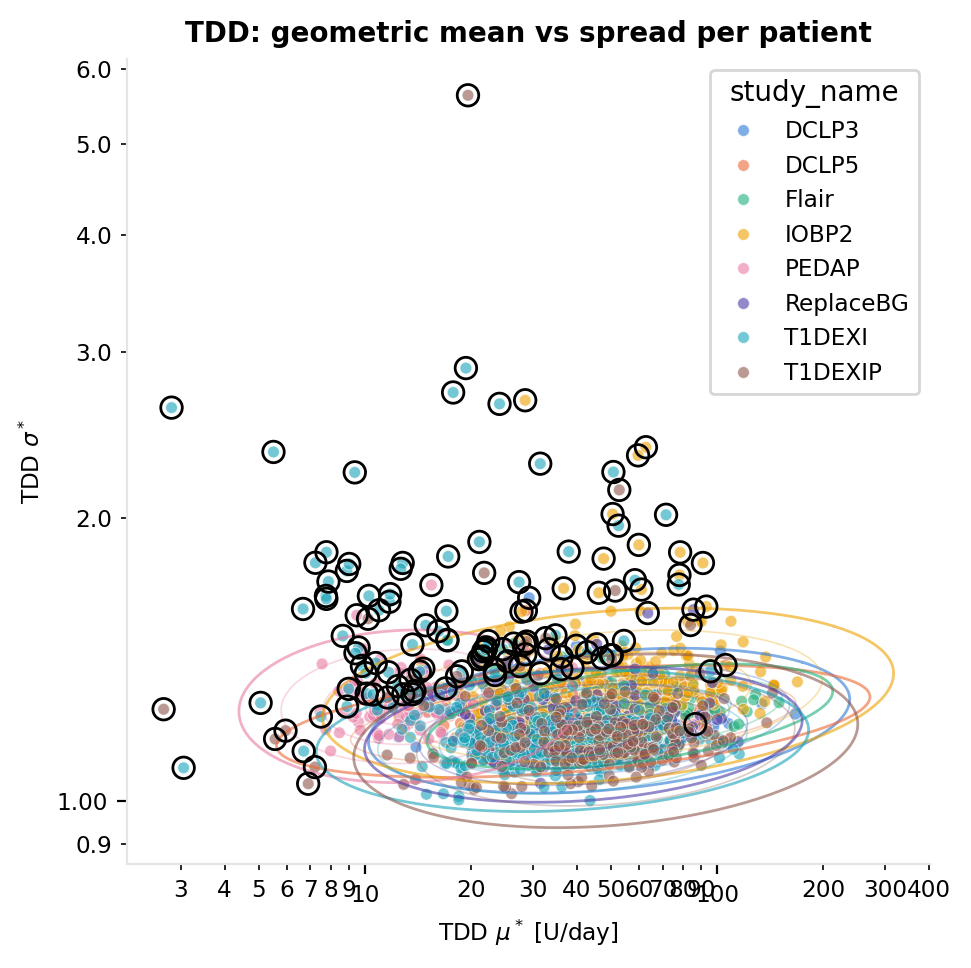

In [10]:
# mean vs std
valid = df_tdd[df_tdd.tdd >= MIN_TDD].groupby(KEYS, observed=True).tdd
df_tdd_patient = pd.DataFrame({
    'mu': valid.agg(gmean),
    'sigma': valid.agg(lambda x: gstd(x) if len(x) > 1 else np.nan),  # undefined for a single day
})
display("Study Medians:")
print(df_tdd_patient.groupby('study_name', observed=True).median())

f, ax = drawing.default_figure(5, 5)
sns.scatterplot(df_tdd_patient, x='mu', y='sigma', hue='study_name', hue_order=STUDIES, palette=PALETTE, s=18, alpha=0.6, ax=ax)
outliers = []
for study, df in df_tdd_patient[['mu', 'sigma']].dropna().groupby('study_name', observed=True):
    fit = fit_population(df, log=True, robust=True)
    plot_confidence_ellipses(fit, ax, log=True, n_stds=[1, 2, 3], color=PALETTE[study], linestyle='-', linewidth=0.6, alpha=0.3)
    plot_confidence_ellipses(fit, ax, log=True, n_stds=[THRESHOLD], color=PALETTE[study], linestyle='-', linewidth=1)
    outlier, distance = find_outliers(df, fit, THRESHOLD, log=True)
    ax.scatter(df.mu[outlier], df.sigma[outlier], s=60, facecolors='none', edgecolors='black', linewidths=1, zorder=5)
    outliers.append(df[outlier].assign(distance=distance[outlier]))
ax.set(xscale='log', yscale='log', xlabel=r'TDD $\mu^*$ [U/day]', ylabel=r'TDD $\sigma^*$', title='TDD: geometric mean vs spread per patient')
ax.xaxis.set_major_formatter(ScalarFormatter())
ax.xaxis.set_minor_formatter(ScalarFormatter())
ax.yaxis.set_major_formatter(ScalarFormatter())
ax.yaxis.set_minor_formatter(ScalarFormatter())
plt.tight_layout()
f.savefig(os.path.join(FIGURE_DIR, f"verification_tdd_mean_vs_spread.png"), dpi=300, bbox_inches="tight")

display("Outliers:")
display(pd.concat(outliers).sort_values('distance', ascending=False).head(TOP_N))


### Bolus vs. Basal (per day) (just visual inspection)

basal  bolus   distance
study_name patient_id date                               
IOBP2      480        2020-08-22  34.56  0.015  19.522110
           107        2020-07-12  48.96  0.088  15.809845
           440        2019-11-07  17.28  0.045  15.719431

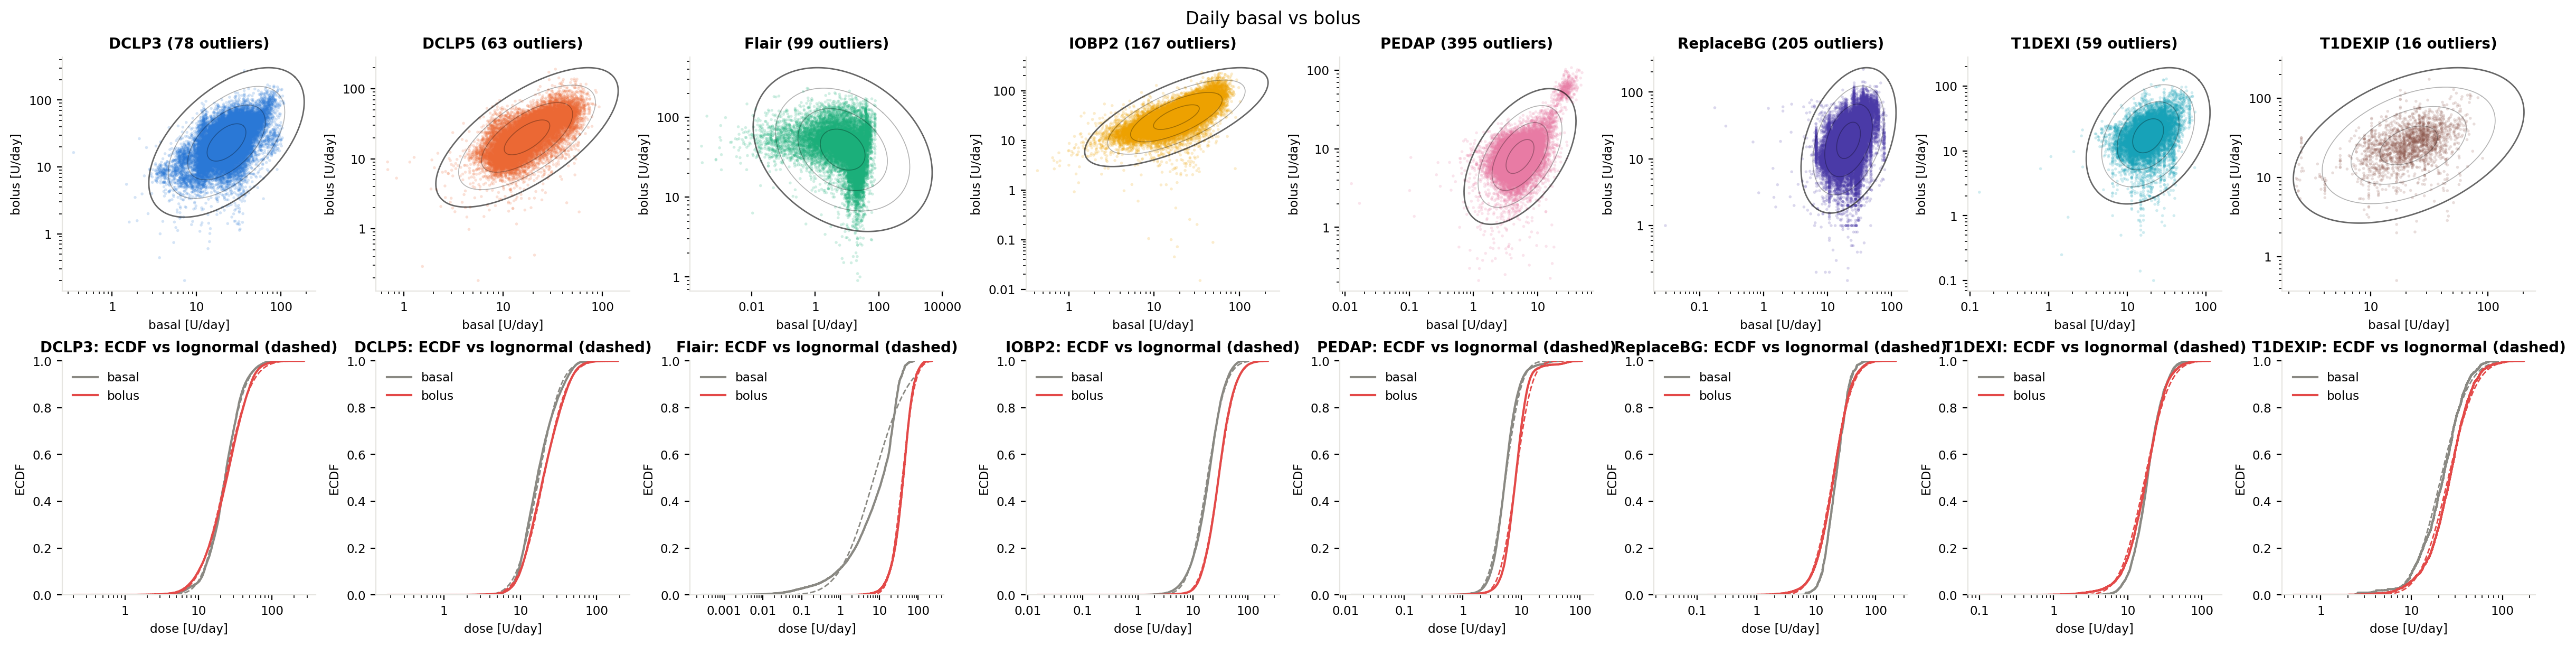

In [11]:
from scipy.stats import lognorm

f, AX = plt.subplots(2, len(STUDIES), figsize=(3 * len(STUDIES), 6), layout='constrained', squeeze=False)
f.suptitle('Daily basal vs bolus')

outliers = []
for study, (ax, ax_ecdf) in zip(STUDIES, AX.T):
    df = df_tdd.xs(study, level='study_name', drop_level=False)[['basal', 'bolus']].dropna()
    df = df[(df.basal > 0) & (df.bolus > 0)]  # exclude zero doses
    fit = fit_population(df, log=True, robust=False)
    outlier, distance = find_outliers(df, fit, THRESHOLD, log=True)
    outliers.append(df[outlier].assign(distance=distance[outlier]))

    # contour first: it resets the axis limits to itself, the scatter afterwards extends them again
    plot_confidence_ellipses(fit, ax, log=True, n_stds=[1, 2, 3], color='black', linestyle='-', linewidth=0.6, alpha=0.3)
    plot_confidence_ellipses(fit, ax, log=True, n_stds=[THRESHOLD], color='black', linestyle='-', linewidth=1)
    ax.scatter(df.basal, df.bolus, s=4, alpha=0.2, color=PALETTE[study], edgecolors='none')
    ax.set(xscale='log', yscale='log', xlabel='basal [U/day]', ylabel='bolus [U/day]',
           title=f'{study} ({outlier.sum()} outliers)')
    ax.xaxis.set_major_formatter('{x:g}')
    ax.yaxis.set_major_formatter('{x:g}')

    # marginals of the fit: mean and SD of the log values per column
    mean, std = fit.location_, np.sqrt(np.diag(fit.covariance_))
    for i, column in enumerate(['basal', 'bolus']):
        color = drawing.colors[column.capitalize()]
        x = np.geomspace(df[column].min(), df[column].max(), 200)
        ax_ecdf.ecdf(df[column], color=color, label=column)
        ax_ecdf.plot(x, lognorm(s=std[i], scale=np.exp(mean[i])).cdf(x), color=color, linestyle='--', linewidth=1)
    ax_ecdf.set(xscale='log', xlabel='dose [U/day]', ylabel='ECDF', title=f'{study}: ECDF vs lognormal (dashed)')
    ax_ecdf.xaxis.set_major_formatter('{x:g}')
    ax_ecdf.legend(frameon=False)

f.savefig(os.path.join(FIGURE_DIR, f"verification_daily_basal_vs_bolus.png"), dpi=300, bbox_inches="tight")

df_outliers = pd.concat(outliers).sort_values('distance', ascending=False)
df_outliers[~df_outliers.index.droplevel('date').duplicated()].head(3)  # most extreme day of each subject


### CGM

A gap is irregular when it is not a multiple of 5 min (±5 s). Runs of irregular gaps up to 30 min form a section; longer gaps are dropouts or sensor changes. A section of at least 12 gaps that averages 2.5 min per gap is two interleaved sensors. An hour jump is a gap of exactly n hours plus the patient's median gap (±1 s). Rate of change uses gaps up to 15 min.

,,irregular_hours,hour_jumps,cgm_mean,rate_of_change
study_name,patient_id,,,,
DCLP5,64,742.142778,6,122.797749,0.783459
T1DEXI,1120,619.748056,0,136.127198,1.894311
DCLP5,92,592.706389,10,172.263125,1.201360
T1DEXI,484,517.050000,0,129.429916,0.889144
DCLP5,30,484.634444,16,147.017768,1.268142


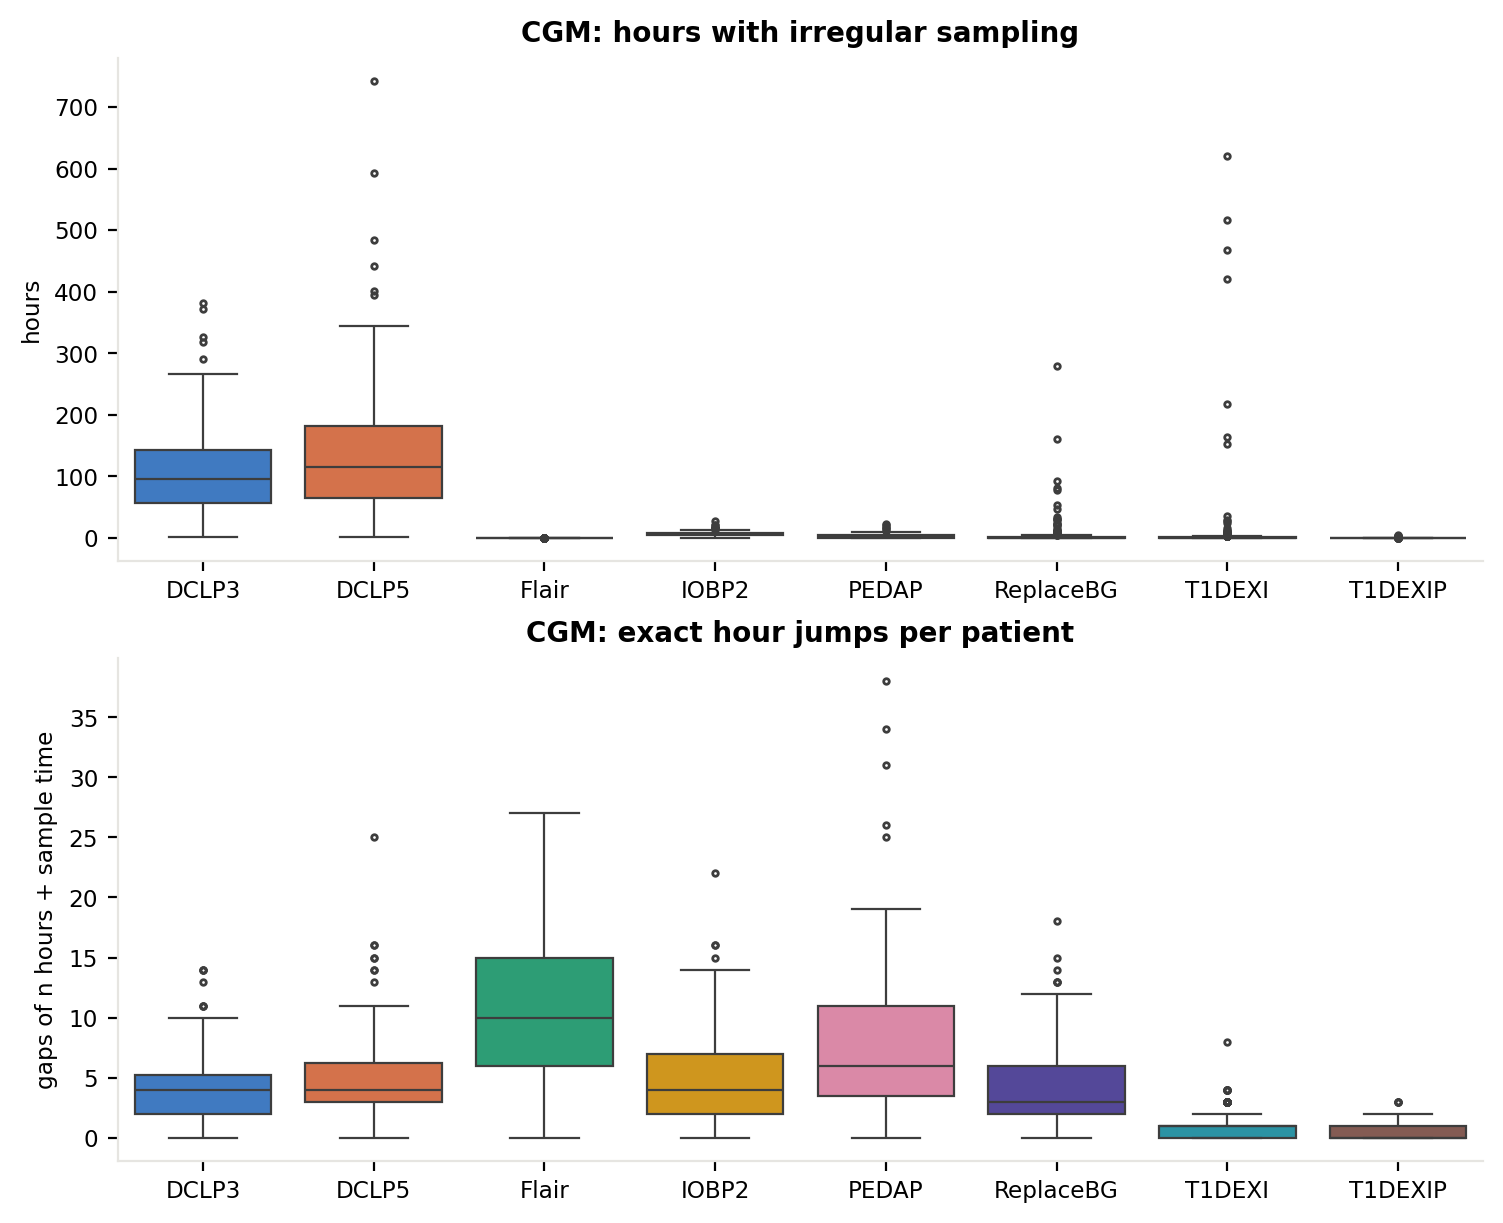

In [12]:
# gap to the previous reading of the same patient [s]
df_gaps = store['cgm'].sort_values(KEYS + ['datetime'])
patient = df_gaps.groupby(KEYS, observed=True)
df_gaps['gap'] = patient.datetime.diff().dt.total_seconds()

# irregular: not a multiple of 5 min (±10 s); gaps above 30 min are dropouts, not a wrong rate
rest = df_gaps.gap % 300
irregular = (rest > 10) & (rest < 290) & (df_gaps.gap <= 1800)

# sensor change: an irregular gap longer than 5 min followed by regular sampling (likely a sensor change)
phase_shift = irregular & (df_gaps.gap > 305) & ~irregular.shift(-1, fill_value=False)

df_gaps['irregular_seconds'] = df_gaps.gap.where(irregular & ~phase_shift, 0)

# hour jump: gap of exactly n hours plus the patient's usual gap (±1 s)
rest = (df_gaps.gap - patient.gap.transform('median')) % 3600
df_gaps['hour_jump'] = (df_gaps.gap > 3600) & ((rest <= 10) | (rest >= 3590))

# rate of change [mg/dL/min], only across gaps up to 15 min
df_gaps['roc'] = (patient.cgm.diff().abs() / (df_gaps.gap / 60)).where(df_gaps.gap <= 900)

# metrics per patient
patient = df_gaps.groupby(KEYS, observed=True)
df_cgm_patient = pd.DataFrame({
    'irregular_hours': patient.irregular_seconds.sum() / 3600,
    'hour_jumps': patient.hour_jump.sum(),
    'cgm_mean': patient.cgm.mean(),
    'rate_of_change': patient.roc.mean(),
})
df_cgm_patient.groupby('study_name', observed=True).median()

f, AX = plt.subplots(2, 1, figsize=(1 + 0.8 * len(STUDIES), 6), layout='constrained')
for ax, (column, ylabel, title) in zip(AX, [('irregular_hours', 'hours', 'CGM: hours with irregular sampling'),
                                           ('hour_jumps', 'gaps of n hours + sample time', 'CGM: exact hour jumps per patient')]):
    sns.boxplot(df_cgm_patient.reset_index(), x='study_name', y=column, hue='study_name', order=STUDIES, hue_order=STUDIES,
                palette=PALETTE, dodge=False, linewidth=0.8, flierprops=dict(marker='.', markersize=4), ax=ax)
    ax.set(xlabel=None, ylabel=ylabel, title=title)

f.savefig(os.path.join(FIGURE_DIR, f"verification_cgm_irregular_hours_and_jumps.png"), dpi=300, bbox_inches="tight")

df_cgm_patient.sort_values('irregular_hours', ascending=False).head(5)


In [13]:
# hours = df_cgm_patient.irregular_hours
# examples = {'many': hours.idxmax(), 'few': hours[hours > 0].idxmin()}

# f, AX = plt.subplots(2, 1, figsize=(12, 6), layout='constrained')
# for ax, (label, (study, patient_id)) in zip(AX, examples.items()):
#     df = df_gaps[(df_gaps.study_name == study) & (df_gaps.patient_id == patient_id)]
#     counted = df[df.irregular_seconds > 0]

#     # 12 h around the middle counted interval
#     center = counted.datetime.iloc[len(counted) // 2]
#     start, end = center - pd.Timedelta(hours=6), center + pd.Timedelta(hours=6)
#     window = df[df.datetime.between(start, end)]
#     shown = counted[counted.datetime.between(start, end)]
#     display(shown)
#     drawing.drawCGM(ax, window.datetime, window.cgm)
#     drawing.shade_gaps(ax, zip(shown.datetime - pd.to_timedelta(shown.gap, unit='s'), shown.datetime))
#     ax.set_title(f'{label}: {study} patient {patient_id}, {hours[(study, patient_id)]:.1f} h irregular in total')
# f.savefig(os.path.join(FIGURE_DIR, f"verification_cgm_irregular_examples.png"), dpi=300, bbox_inches="tight")


#### CGM vs ROC

,,cgm_mean,rate_of_change,distance
study_name,patient_id,,,
PEDAP,29,149.728906,8.574287,19.237047
IOBP2,348,378.417293,0.394487,16.511825
DCLP3,164,163.477960,7.119466,14.408440


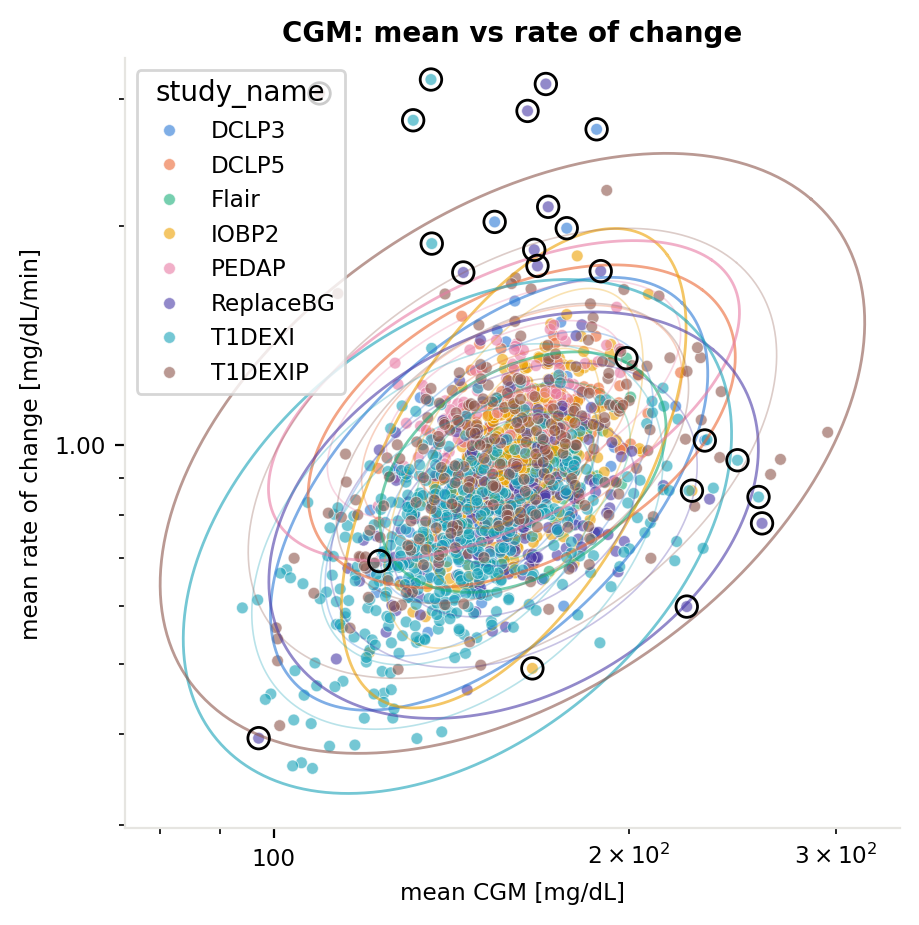

In [14]:
from matplotlib.ticker import ScalarFormatter
f, ax = drawing.default_figure(5, 5)
sns.scatterplot(df_cgm_patient, x='cgm_mean', y='rate_of_change', hue='study_name', hue_order=STUDIES, palette=PALETTE, s=18, alpha=0.6, ax=ax)
outliers = []
for study, df in df_cgm_patient[['cgm_mean', 'rate_of_change']].dropna().groupby('study_name', observed=True):
    fit = fit_population(df, log=True, robust=True)
    plot_confidence_ellipses(fit, ax, log=True, n_stds=[1, 2, 3], color=PALETTE[study], linestyle='-', linewidth=0.6, alpha=0.3)
    plot_confidence_ellipses(fit, ax, log=True, n_stds=[THRESHOLD], color=PALETTE[study], linestyle='-', linewidth=1)
    outlier, distance = find_outliers(df, fit, THRESHOLD, log=True)
    ax.scatter(df.cgm_mean[outlier], df.rate_of_change[outlier], s=60, facecolors='none', edgecolors='black', linewidths=1, zorder=5)
    outliers.append(df[outlier].assign(distance=distance[outlier]))
ax.set(xlabel='mean CGM [mg/dL]', ylabel='mean rate of change [mg/dL/min]', title='CGM: mean vs rate of change')
ax.set(xscale='log', yscale='log')
ax.xaxis.set_major_formatter(ScalarFormatter())
ax.yaxis.set_major_formatter(ScalarFormatter())
f.savefig(os.path.join(FIGURE_DIR, f"verification_cgm_mean_vs_roc.png"), dpi=300, bbox_inches="tight")

pd.concat(outliers).sort_values('distance', ascending=False).head(TOP_N)

## Data Coverage

**Data coverage**: Share of days with *any data* between a patient's first and last day.   
**Data completeness**: Share of those days that have *all streams*.

,,total_days,complete_days,total_vs_median,completeness_ratio,distance
study_name,patient_id,,,,,
IOBP2,395,3,1,0.031915,0.333333,1.175429
DCLP5,54,416,185,2.009662,0.444712,1.152286
PEDAP,75,4,2,0.015504,0.500000,1.104189


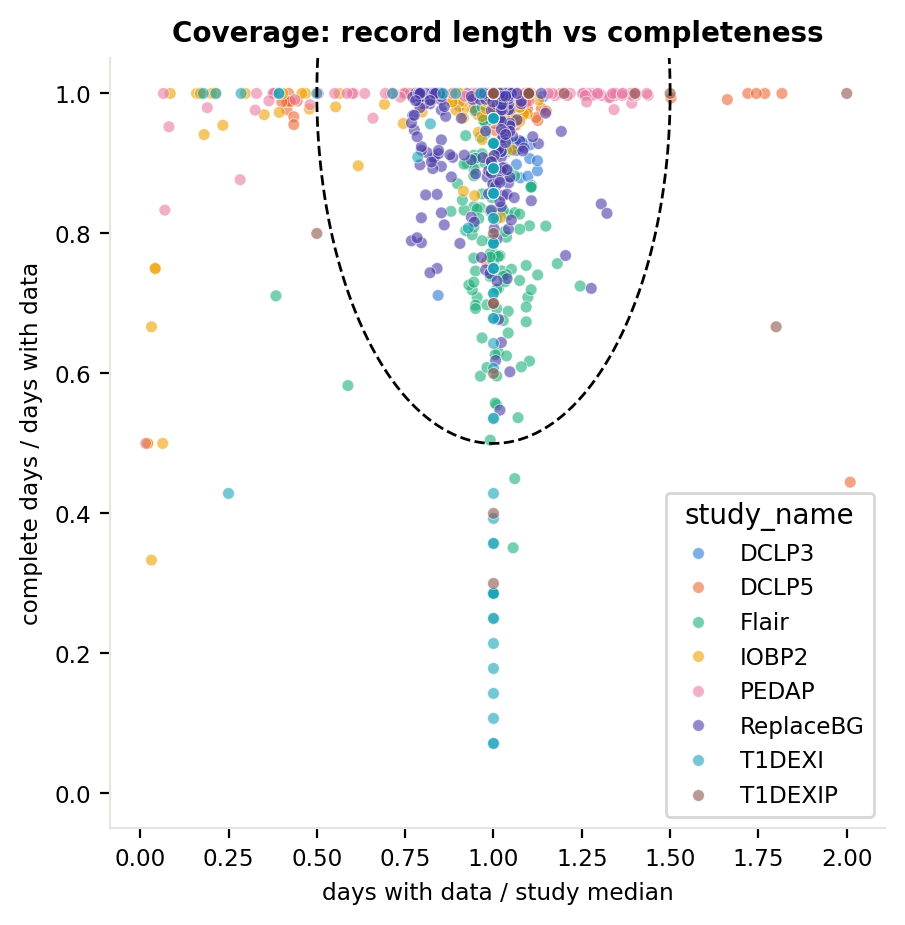

In [15]:
# count streams with data per patient and day
df_days = pd.concat([store[s][KEYS].assign(date=store[s].datetime.dt.normalize()).drop_duplicates() for s in STREAMS])
df_streams_per_day = df_days.groupby(KEYS + ['date'], observed=True).size().rename('streams').reset_index()

df_coverage = (df_streams_per_day.groupby(KEYS, observed=True)
    .agg(total_days=('date', 'size'), 
         complete_days=('streams', lambda s: (s >= len(STREAMS)).sum())))

#exclude patients without any data
df_coverage = df_coverage[~df_coverage.index.isin(df_missing_stream.index)]

#calcualte metrics
df_coverage['total_vs_median'] = df_coverage.total_days / df_coverage.groupby('study_name', observed=True).total_days.transform('median')
df_coverage['completeness_ratio'] = df_coverage.complete_days / df_coverage.total_days
df_coverage['distance'] = np.hypot(df_coverage.total_vs_median - 1, df_coverage.completeness_ratio - 1)

COVERAGE_LIMIT = 0.5  # distance from (1, 1) worth inspecting

# plot record length vs completeness with the limit circle
f, ax = drawing.default_figure(5, 5)
sns.scatterplot(df_coverage, x='total_vs_median', y='completeness_ratio', hue='study_name', hue_order=STUDIES, palette=PALETTE, s=18, alpha=0.6, ax=ax)
theta = np.linspace(0, 2 * np.pi, 200)
ax.plot(1 + COVERAGE_LIMIT * np.cos(theta), 1 + COVERAGE_LIMIT * np.sin(theta), color='black', linewidth=1, linestyle='--')
ax.set(xlabel='days with data / study median',
       ylabel='complete days / days with data', title='Coverage: record length vs completeness',
       ylim=(-0.05, 1.05))
f.savefig(os.path.join(FIGURE_DIR, f"verification_coverage.png"), dpi=300, bbox_inches="tight")

# most extreme patients per study outside the limit
(df_coverage[df_coverage.distance > COVERAGE_LIMIT]
    .sort_values('distance', ascending=False)
    #.groupby('study_name', observed=True)
    .head(TOP_N))#.reset_index().sort_values(['study_name','distance'])
